In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
df=pd.read_csv('/content/Position_Salaries.csv')
print("Dataset is loaded Successfully")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


In [ ]:
df.describe()

,Level,Salary
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


In [ ]:
df.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [ ]:
df.shape

(10, 3)

In [ ]:
df.isnull().sum()

,0
Position,0
Level,0
Salary,0


In [ ]:
# Check duplicate records
print(df.duplicated().sum())
# Remove duplicates if any
df.drop_duplicates(inplace=True)

0


<Axes: ylabel='Level'>

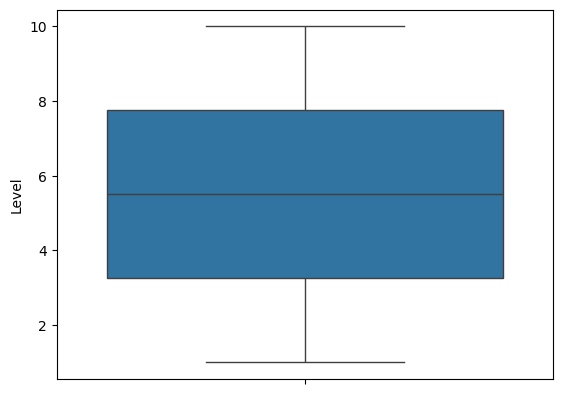

In [ ]:
#Outlier detection
sns.boxplot(df['Level'])

In [ ]:
x=df['Level']
y=df['Salary']

Text(0, 0.5, 'Salary')

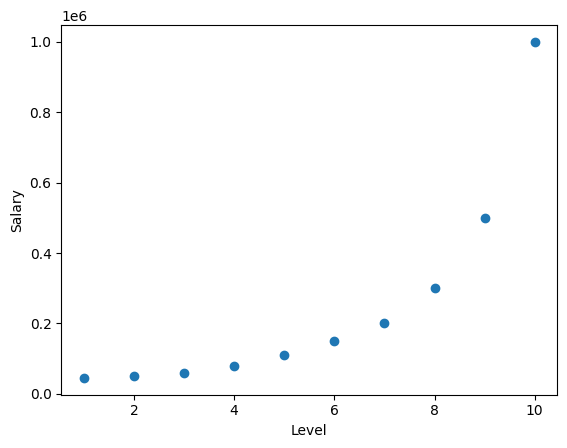

In [ ]:
plt.scatter(x,y)
plt.xlabel('Level')
plt.ylabel('Salary')

In [ ]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=123)

In [ ]:
print(f"Number of instances for training: {len(x_train)}")
print(f"Number of instances for testing: {len(x_test)}")

Number of instances for training: 8
Number of instances for testing: 2


In [ ]:
poly_features=PolynomialFeatures(degree=5)
x_train_poly = poly_features.fit_transform(x_train.to_frame())

In [ ]:
lr_model=LinearRegression()
lr_model.fit(x_train_poly,y_train)

LinearRegression()

In [ ]:
lr_model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
x_test_poly = poly_features.transform(x_test.to_frame())
y_pred = lr_model.predict(x_test_poly)
df=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(df)

   Actual      Predicted
4  110000  108360.049321
0   45000  -25343.197710


In [ ]:
# Evaluate model performance on training data using MAE, MSE, RMSE, and R2 score
y_train_pred = lr_model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 2785.0088668361786
Mean Squared Error (MSE): 11226607.342511918
Root MSE (RMSE): 3350.612980114522
R2 Score: 0.9998770613116965


In [ ]:
# Evaluate model performance on testing data using MAE, MSE, RMSE, and R2 score
x_test_poly = poly_features.transform(x_test.to_frame())
y_test_pred = lr_model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score: ", r2)

Mean Absolute Error (MAE): 35991.574194545596
Mean Squared Error (MSE): 2475427451.1300235
Root MSE (RMSE): 49753.66771535565
R2 Score:  0.9998770613116965


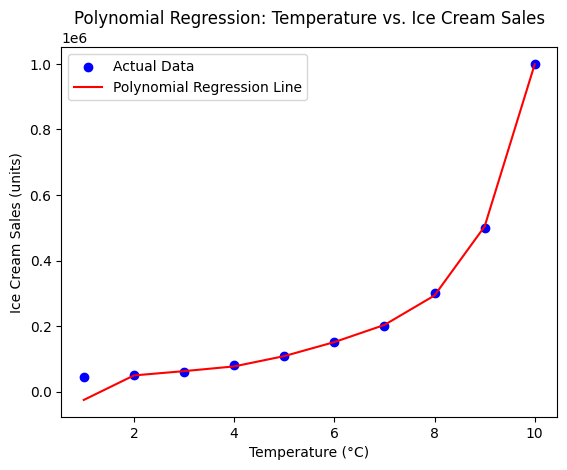

In [ ]:
plt.scatter(x, y, color='blue', label='Actual Data')
plt.plot(x, lr_model.predict(poly_features.transform(x.to_frame())), color='red', label='Polynomial Regression Line')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.title('Polynomial Regression: Level vs. Salary')
plt.legend()
plt.show()